<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="310" alt="Query.Farm Strata Sun and wordmark"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="115" alt="VGI logo"></a>

# How often do reported market prices depart from NAV?

For **VOO** and **BND**, turn Vanguard’s paired daily price history into a basis-point difference, then count observations outside a chosen symmetric band. A time plot locates the unusual observations; a threshold curve shows how the answer changes when “unusual” gets a tighter definition.

This uses the real Vanguard worker through Haybarn/VGI, with **live** one-year histories and no fixture fallback. A matching calendar date is the worker’s join key; it does not establish identical valuation times or an executable price. The differences below are descriptive observations, not trading signals, total returns, spreads, or transaction costs.

## Choose the comparison band

`BAND_BPS` is a positive threshold in **basis points**: 1 bp = 0.01 percentage point. The default ±10 bp band flags an observation only when the **absolute** difference is **strictly greater** than 10 bp; equality remains inside. Accepted values are 0.5–50 bp. The source period stays fixed at `1Y`, which supplies daily observations; `5Y` and `10Y` use different sampling frequencies and would change the question. Restart and run all after editing.

In [1]:
BAND_BPS = 10.0  # Symmetric threshold in basis points; experiment: 5.0.

In [2]:
from datetime import UTC, datetime

import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import COLORS, finish, prose, theme

if type(BAND_BPS) not in (int, float) or not np.isfinite(BAND_BPS) or not 0.5 <= BAND_BPS <= 50:
    raise ValueError("BAND_BPS must be a finite number from 0.5 through 50.")
retrieved_utc = datetime.now(UTC).isoformat(timespec="seconds")
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-vanguard/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-vanguard/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-vanguard/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-vanguard/notebooks/pyproject.toml.

## Connect and materialize each live response

The pinned native worker downloads automatically. Each function call is materialized once before any DataFrame capture, so tables and charts reuse local results. The catalog identifies the two funds; its current prices are not substituted into their historical rows. Each history is a separate request, so the two responses are not an atomic snapshot.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'vanguard' AS vg (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-etf-vanguard@v0.4.0');
CREATE TABLE selected_funds(ticker VARCHAR);
INSERT INTO selected_funds VALUES ('VOO'), ('BND');
CREATE TABLE products AS SELECT ticker, long_name, asset_class, price_as_of
FROM vg.main.products WHERE ticker IN ('VOO', 'BND');
CREATE TABLE history AS
SELECT 'VOO' AS ticker, * FROM vg.main.nav_history('VOO', period := '1Y')
UNION ALL
SELECT 'BND' AS ticker, * FROM vg.main.nav_history('BND', period := '1Y');

2 rows affected.

2 rows affected.

502 rows affected.

,Count


## Keep missing pairs out of the denominator

The worker walks **NAV dates** and looks up the market price with the same date; dates appearing only in the market-price series are not returned. We inspect the returned NAV-date list, not a complete exchange calendar. Missing, nonpositive or nonfinite prices cannot support the ratio, so they remain unavailable rather than becoming zero differences. No dates are filled or interpolated.

In [4]:
%%sql
CREATE TABLE observed AS
SELECT *, coalesce(as_of_date IS NOT NULL AND nav > 0 AND market_price > 0
                   AND isfinite(nav) AND isfinite(market_price), false) AS valid_pair
FROM history;
CREATE TABLE availability AS
SELECT f.ticker, p.long_name, p.asset_class, p.price_as_of AS catalog_date,
       count(h.ticker) AS returned_nav_dates,
       count(*) FILTER (WHERE h.ticker IS NOT NULL AND h.nav IS NULL) AS missing_nav,
       count(*) FILTER (WHERE h.ticker IS NOT NULL AND h.market_price IS NULL) AS missing_market_price,
       count(*) FILTER (WHERE h.ticker IS NOT NULL AND NOT h.valid_pair) AS unavailable_pairs,
       count(*) FILTER (WHERE h.valid_pair) AS valid_pairs,
       min(h.as_of_date) AS first_returned_date, max(h.as_of_date) AS last_returned_date
FROM selected_funds f LEFT JOIN products p USING (ticker) LEFT JOIN observed h USING (ticker)
GROUP BY f.ticker, p.long_name, p.asset_class, p.price_as_of;
CREATE TABLE paired AS
SELECT ticker, as_of_date, nav, market_price, market_price - nav AS difference_usd_per_share,
       10000.0 * (market_price - nav) / nav AS difference_bps
FROM observed WHERE valid_pair;

502 rows affected.

2 rows affected.

502 rows affected.

,Count


In [5]:
%%sql availability <<
SELECT * FROM availability ORDER BY ticker;

In [6]:
display(availability)
prose(
    f"Retrieval started at **{retrieved_utc}**. Each fund’s actual returned date range is shown above. "
    "NAV and market price are reported USD per share; dividing their difference by NAV removes "
    "the per-share unit, and multiplying by **10,000** expresses the ratio in basis points. "
    "Positive values mean market price exceeds NAV; negative values mean it is below NAV."
)

,ticker,long_name,asset_class,catalog_date,returned_nav_dates,missing_nav,missing_market_price,unavailable_pairs,valid_pairs,first_returned_date,last_returned_date
0,BND,Vanguard Total Bond Market ETF,Fixed Income,2026-11-13,251,0,0,0,251,2025-11-14,2026-11-13
1,VOO,Vanguard S&P 500 ETF,Equity,2026-11-13,251,0,0,0,251,2025-11-14,2026-11-13


Retrieval started at **2026-11-14T06:36:11+00:00**. Each fund’s actual returned date range is shown above. NAV and market price are reported USD per share; dividing their difference by NAV removes the per-share unit, and multiplying by **10,000** expresses the ratio in basis points. Positive values mean market price exceeds NAV; negative values mean it is below NAV.

In [7]:
%%sql source_checks <<
SELECT 'both requested funds are identified and populated' AS check_name,
       count(*) = 2 AND bool_and(long_name IS NOT NULL AND valid_pairs >= 20) AS passed FROM availability
UNION ALL SELECT 'fund and returned NAV-date keys are unique',
       count(*) = count(DISTINCT (ticker, as_of_date)) AND count(as_of_date) = count(*) FROM observed
UNION ALL SELECT 'availability accounts for every returned NAV date',
       bool_and(valid_pairs + unavailable_pairs = returned_nav_dates) FROM availability
UNION ALL SELECT 'valid price pairs are finite and positive',
       bool_and(nav > 0 AND market_price > 0 AND isfinite(nav) AND isfinite(market_price)) FROM paired
UNION ALL SELECT 'basis points reconstruct the USD difference',
       bool_and(abs(difference_bps * nav / 10000 - difference_usd_per_share) < 1e-8) FROM paired;

In [8]:
display(source_checks)
assert source_checks.passed.fillna(False).all(), "Required paired-price coverage failed."

,check_name,passed
0,both requested funds are identified and populated,True
1,fund and returned NAV-date keys are unique,True
2,availability accounts for every returned NAV date,True
3,valid price pairs are finite and positive,True
4,basis points reconstruct the USD difference,True


## Apply the band with a stated denominator

The denominator is each fund’s **valid returned price pairs**, not an assumed 252 trading days. We separate observations below the negative band, inside the inclusive band, and above the positive band. Maximum absolute difference and median absolute difference distinguish an isolated large departure from the typical observation.

In [9]:
%%sql
CREATE TABLE summary AS
SELECT ticker, count(*) AS observations, min(as_of_date) AS first_date, max(as_of_date) AS last_date,
       count(*) FILTER (WHERE difference_bps < -{{BAND_BPS}}) AS below_band,
       count(*) FILTER (WHERE abs(difference_bps) <= {{BAND_BPS}}) AS inside_band,
       count(*) FILTER (WHERE difference_bps > {{BAND_BPS}}) AS above_band,
       count(*) FILTER (WHERE abs(difference_bps) > {{BAND_BPS}}) AS outside_band,
       100.0 * count(*) FILTER (WHERE abs(difference_bps) > {{BAND_BPS}}) / count(*) AS outside_percent,
       median(abs(difference_bps)) AS median_absolute_bps, max(abs(difference_bps)) AS maximum_absolute_bps
FROM paired GROUP BY ticker;

2 rows affected.

,Count


In [10]:
%%sql summary <<
SELECT * FROM summary ORDER BY ticker;

In [11]:
display(summary)

,ticker,observations,first_date,last_date,below_band,inside_band,above_band,outside_band,outside_percent,median_absolute_bps,maximum_absolute_bps
0,BND,251,2025-11-14,2026-11-13,0,250,1,1,0.398406,2.766634,12.325390
1,VOO,251,2025-11-14,2026-11-13,2,249,0,2,0.796813,1.724435,45.594285


In [12]:
%%sql prices <<
SELECT * FROM paired ORDER BY ticker, as_of_date;

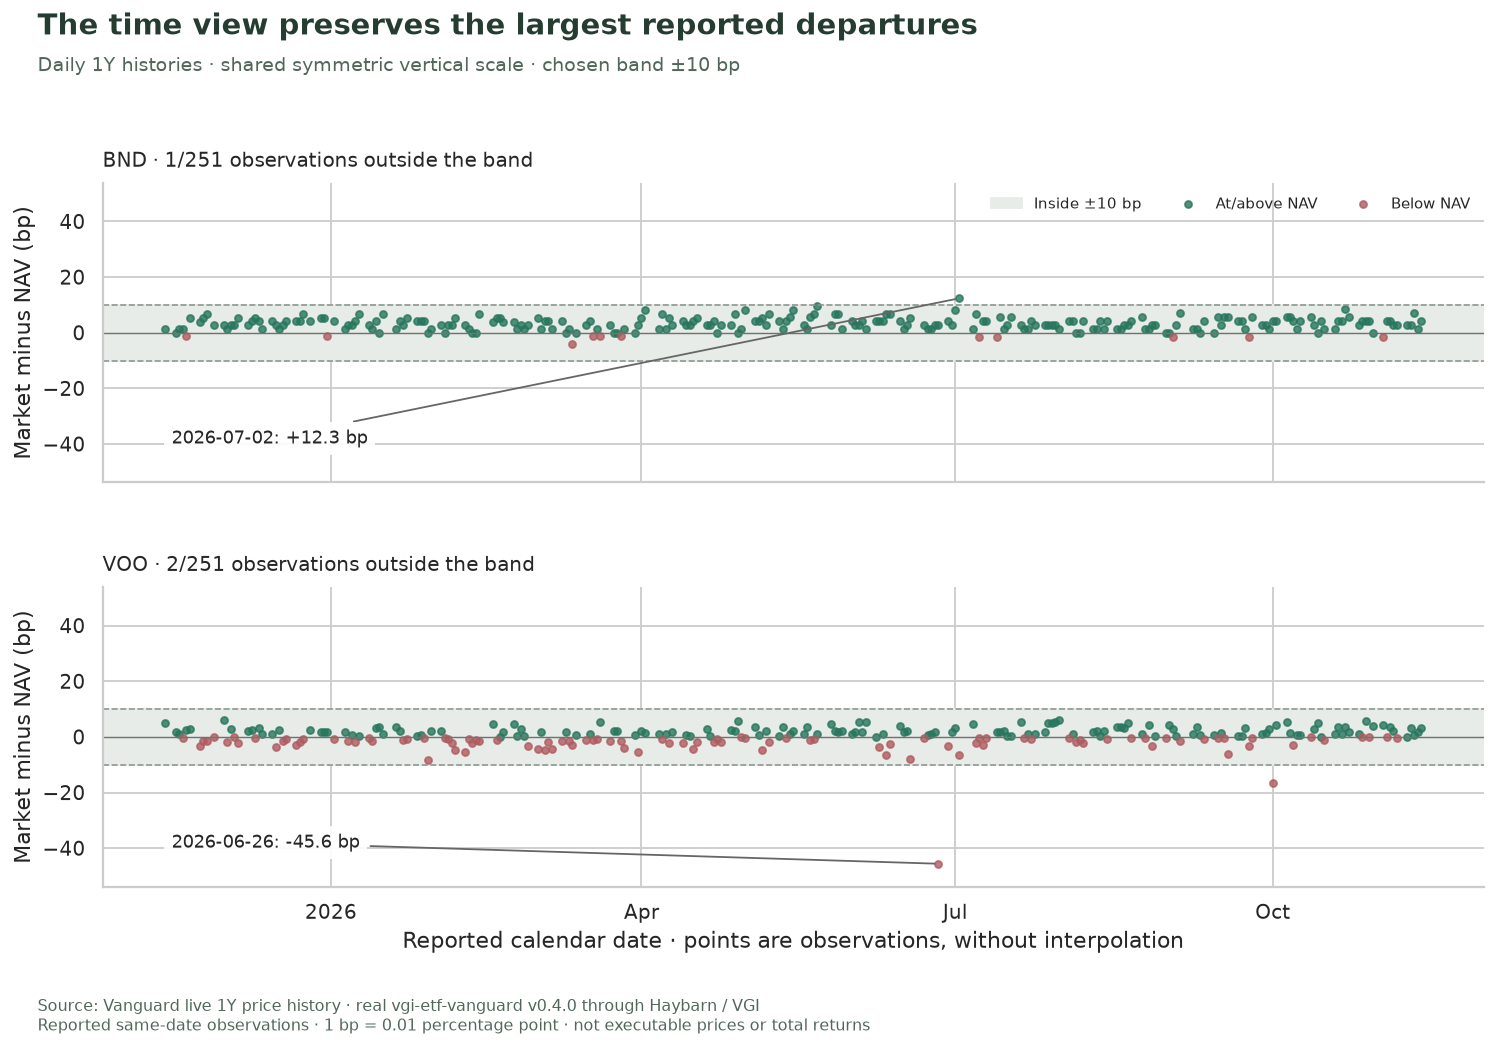

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12.5, 8.2), sharex=True, sharey=True)
limit = max(prices.difference_bps.abs().max(), BAND_BPS) * 1.18
for ax, row in zip(axes, summary.itertuples(), strict=True):
    group = prices.loc[prices.ticker == row.ticker]
    ax.axhspan(-BAND_BPS, BAND_BPS, color="#e8ece9", label=f"Inside ±{BAND_BPS:g} bp")
    ax.axhline(0, color="#6d756f", linewidth=0.8)
    ax.axhline(BAND_BPS, color="#8b9690", linestyle="--", linewidth=0.9)
    ax.axhline(-BAND_BPS, color="#8b9690", linestyle="--", linewidth=0.9)
    for positive, color, label in [(True, "#27765d", "At/above NAV"), (False, "#b05b60", "Below NAV")]:
        subset = group.loc[(group.difference_bps >= 0) == positive]
        ax.scatter(subset.as_of_date, subset.difference_bps, s=15, color=color, alpha=0.8, label=label)
    worst = group.loc[group.difference_bps.abs().idxmax()]
    ax.annotate(
        f"{worst.as_of_date:%Y-%m-%d}: {worst.difference_bps:+.1f} bp",
        xy=(worst.as_of_date, worst.difference_bps),
        xytext=(0.05, 0.13),
        textcoords="axes fraction",
        fontsize=10,
        arrowprops={"arrowstyle": "-", "color": "#666666"},
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
    )
    ax.set_title(
        f"{row.ticker} · {row.outside_band}/{row.observations} observations outside the band",
        loc="left",
        fontsize=11,
        pad=9,
    )
    ax.set_ylabel("Market minus NAV (bp)")
    ax.set_ylim(-limit, limit)
axes[0].legend(loc="upper right", ncols=3, fontsize=8.5, frameon=False)
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=7))
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[-1].xaxis.get_major_locator()))
axes[-1].set_xlabel("Reported calendar date · points are observations, without interpolation")
fig.subplots_adjust(left=0.11, right=0.96, bottom=0.16, top=0.82, hspace=0.35)
finish(
    fig,
    "The time view preserves the largest reported departures",
    f"Daily 1Y histories · shared symmetric vertical scale · chosen band ±{BAND_BPS:g} bp",
    f"history-band-{BAND_BPS:g}.png",
)

In [14]:
sentences = []
for row in summary.itertuples():
    sentences.append(
        f"**{row.ticker}** has **{row.outside_band}/{row.observations} observations "
        f"({row.outside_percent:.1f}%)** outside ±{BAND_BPS:g} bp. "
        f"Its median absolute difference is **{row.median_absolute_bps:.2f} bp**, "
        f"versus a maximum of **{row.maximum_absolute_bps:.2f} bp**."
    )
prose(
    " ".join(sentences) + " The plotted extreme is retained, not trimmed. These records alone cannot "
    "explain a departure or establish that a trade could have captured it."
)

**BND** has **1/251 observations (0.4%)** outside ±10 bp. Its median absolute difference is **2.77 bp**, versus a maximum of **12.33 bp**. **VOO** has **2/251 observations (0.8%)** outside ±10 bp. Its median absolute difference is **1.72 bp**, versus a maximum of **45.59 bp**. The plotted extreme is retained, not trimmed. These records alone cannot explain a departure or establish that a trade could have captured it.

## Make the threshold choice visible

For each candidate cutoff, SQL counts valid pairs whose absolute difference is **strictly greater** than that cutoff. The curve focuses on cutoffs from zero to at least 15 bp, but **every valid observation**, including larger departures, remains in each count. A higher cutoff cannot increase the flagged fraction for the same data. This is an empirical frequency in the retrieved sample, not a probability forecast.

In [15]:
%%sql tail <<
WITH cutoffs AS (
    SELECT DISTINCT abs(difference_bps) AS cutoff_bps FROM paired
    WHERE abs(difference_bps) <= greatest(15.0, {{BAND_BPS}} * 1.2)
    UNION SELECT 0.0 UNION SELECT greatest(15.0, {{BAND_BPS}} * 1.2)
    UNION SELECT {{BAND_BPS}}::DOUBLE
)
SELECT p.ticker, c.cutoff_bps,
       count(*) FILTER (WHERE abs(p.difference_bps) > c.cutoff_bps) AS flagged,
       count(*) AS observations,
       100.0 * count(*) FILTER (WHERE abs(p.difference_bps) > c.cutoff_bps) / count(*) AS flagged_percent
FROM paired p CROSS JOIN cutoffs c GROUP BY p.ticker, c.cutoff_bps ORDER BY p.ticker, c.cutoff_bps;

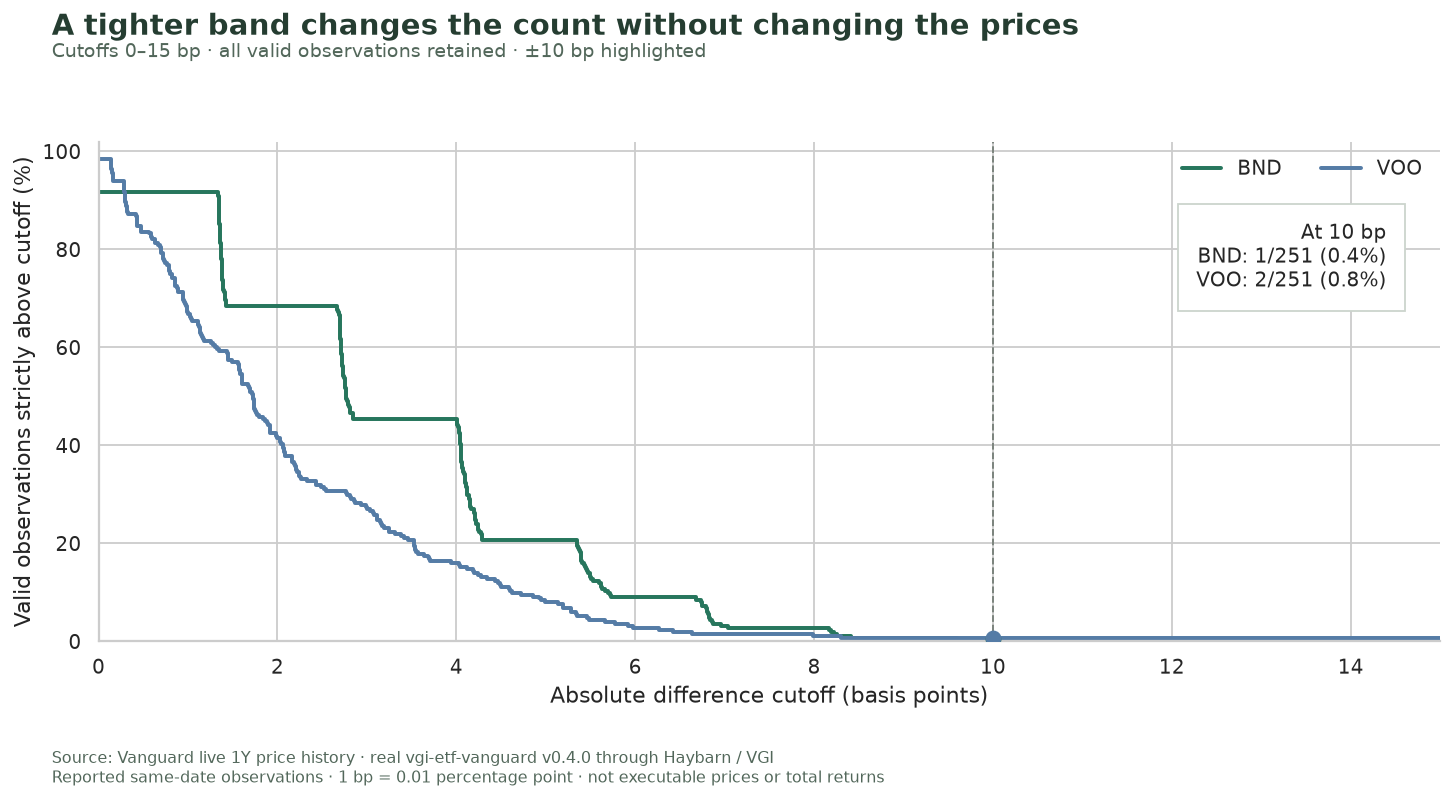

In [16]:
fig, ax = plt.subplots(figsize=(12, 6.2))
for ticker, group in tail.groupby("ticker", sort=True):
    ax.step(group.cutoff_bps, group.flagged_percent, where="post", color=COLORS[ticker], linewidth=2.2, label=ticker)
    chosen = group.loc[np.isclose(group.cutoff_bps, BAND_BPS)].iloc[0]
    ax.scatter([BAND_BPS], [chosen.flagged_percent], color=COLORS[ticker], s=60, zorder=4)
ax.axvline(BAND_BPS, color="#757e77", linestyle="--", linewidth=1)
chosen_text = "\n".join(
    f"{row.ticker}: {row.outside_band}/{row.observations} ({row.outside_percent:.1f}%)" for row in summary.itertuples()
)
ax.text(
    0.96,
    0.84,
    f"At {BAND_BPS:g} bp\n{chosen_text}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox={"facecolor": "white", "edgecolor": "#ccd4cd", "pad": 10},
)
ax.set_xlabel("Absolute difference cutoff (basis points)")
ax.set_ylabel("Valid observations strictly above cutoff (%)")
ax.set_xlim(0, tail.cutoff_bps.max())
ax.set_ylim(0, 102)
ax.legend(loc="upper right", frameon=False, ncols=2)
fig.subplots_adjust(left=0.10, right=0.96, bottom=0.20, top=0.82)
finish(
    fig,
    "A tighter band changes the count without changing the prices",
    f"Cutoffs 0–{tail.cutoff_bps.max():g} bp · all valid observations retained · ±{BAND_BPS:g} bp highlighted",
    f"threshold-band-{BAND_BPS:g}.png",
)

## Reconcile classifications and the threshold curve

Every valid pair must land in exactly one band category. The selected point on the threshold curve must match the earlier summary. The curve must be nonincreasing, with frequencies between 0 and 100%. These checks verify the calculation rather than a particular historical price path.

In [17]:
%%sql arithmetic_checks <<
SELECT 'band categories partition every valid observation' AS check_name,
       bool_and(below_band + inside_band + above_band = observations
                AND below_band + above_band = outside_band) AS passed FROM summary
UNION ALL SELECT 'threshold sample counts agree with summary',
       bool_and(t.flagged = s.outside_band AND t.observations = s.observations)
FROM (SELECT p.ticker, count(*) FILTER (WHERE abs(difference_bps) > {{BAND_BPS}}) AS flagged,
      count(*) AS observations FROM paired p GROUP BY p.ticker) t JOIN summary s USING (ticker)
UNION ALL SELECT 'sample frequencies remain within bounds',
       bool_and(outside_percent BETWEEN 0 AND 100) FROM summary;

In [18]:
display(arithmetic_checks)
assert arithmetic_checks.passed.fillna(False).all(), "Band accounting failed."
curve_monotone = all((group.flagged_percent.diff().dropna() <= 1e-10).all() for _, group in tail.groupby("ticker"))
curve_matches = all(
    int(tail.loc[(tail.ticker == row.ticker) & np.isclose(tail.cutoff_bps, BAND_BPS), "flagged"].iloc[0])
    == row.outside_band
    for row in summary.itertuples()
)
assert curve_monotone and curve_matches, "Threshold curve failed its monotonicity or selected-point check."
prose(
    f"All **{len(source_checks) + len(arithmetic_checks) + 2} source and arithmetic checks** pass. "
    "Unavailable observations are excluded from ratios, and the observed extremes remain in every threshold count."
)

,check_name,passed
0,band categories partition every valid observation,True
1,threshold sample counts agree with summary,True
2,sample frequencies remain within bounds,True


All **10 source and arithmetic checks** pass. Unavailable observations are excluded from ratios, and the observed extremes remain in every threshold count.

## Experiment: tighten the band from 10 to 5 bp

Change **`BAND_BPS = 10.0` to `5.0`**, restart and run all, and compare the outside-band counts. For unchanged input, tightening the band cannot reduce the count. The price points, median, maximum and sample size should remain unchanged; only the classification and highlighted point move. Restore **10.0** for the default.

Every fresh run retrieves the rolling `1Y` window again. Compare the returned ranges, counts and values before attributing changes solely to the threshold; equal dates can still carry issuer revisions. The README provides a separate-output command. This analysis does not include distributions or reinvestment and is not a total-return comparison.

In [19]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="310" alt="Query.Farm Strata Sun and wordmark"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · Sources: [Vanguard VOO](https://investor.vanguard.com/investment-products/etfs/profile/voo) and [BND](https://investor.vanguard.com/investment-products/etfs/profile/bnd)